# Angular and HEALPix lightcones

An angular lightcone holds a field on spherical shells around an observer, one shell per
comoving distance, instead of the planes of a rectilinear lightcone. Each shell is cut
from the simulation box, tiled periodically, and interpolated in redshift between the two
coeval boxes around it.

This tutorial shows the angular lightconers of `tuesday` for 21cmFAST:

* `FastAngularLightconer`, which makes the same lightcones as 21cmFAST's
  `AngularLightconer`, but makes each slice in whichever of two equivalent ways is
  cheaper.
* Pixels that average several directions (sub-samples).
* `healpix_lightconer`, whose slices are HEALPix maps of the full sky or of a patch, and
  the HEALPix helpers of `tuesday.core.lightcones`.
* `plot_angular_lightcone_slice` and `plot_healpix_map` of `tuesday.core`, which plot
  angular lightcones.

It starts with the rectilinear lightcone of the same run, in a figure like Fig. 4 of
Mesinger, Greig & Sobacchi (2016), made with the plotting and power-spectrum functions
of `tuesday`.

All sampling is done by cosmotile's slice interpolators, as in 21cmFAST.

In [1]:
import tempfile
import time
import warnings

import astropy.units as un
import matplotlib.pyplot as plt
import numpy as np
import py21cmfast as p21c
from matplotlib.ticker import NullFormatter, ScalarFormatter
from py21cmfast.io.caching import OutputCache, RunCache

from tuesday.core import (
    calculate_ps_lc,
    eor_colormap,
    lightcones,
    plot_1d_power_spectrum_z,
    plot_angular_lightcone_slice,
    plot_healpix_map,
    plot_lightcone_slice,
)
from tuesday.simulators.py21cmfast.lightconers import (
    FastAngularLightconer,
    healpix_lightconer,
)
from tuesday.simulators.py21cmfast.lightcones import construct_lightcone_from_cache

## A small simulation

The lightconers work on any 21cmFAST run whose coeval boxes are in a cache. Here we run
a small box (64 cells of 3 Mpc on a side) with spin-temperature fluctuations, from
z = 40 down to 6 with node redshifts spaced by a factor of 1.1 in 1 + z, as in
21cmFAST's lightcone tutorial, and keep its 3D velocities, which the line-of-sight
velocity of an angular lightcone needs. The run takes about a minute, and writes the
boxes to a cache, from which the angular lightcones below are made.

In [2]:
inputs = p21c.InputParameters.from_template(
    "simple",
    random_seed=12,
    node_redshifts=p21c.wrapper.inputs.get_logspaced_redshifts(
        min_redshift=6.0, z_step_factor=1.1, max_redshift=40.0
    ),
).evolve_input_structs(
    BOX_LEN=192, HII_DIM=64, DIM=192, KEEP_3D_VELOCITIES=True, USE_TS_FLUCT=True
)
cell = inputs.simulation_options.cell_size
cosmo = inputs.cosmo_params.cosmo

cache = OutputCache(tempfile.mkdtemp())
rect = p21c.run_lightcone(
    lightconer=p21c.RectilinearLightconer.between_redshifts(
        min_redshift=6.1, max_redshift=35.0, resolution=cell
    ),
    inputs=inputs,
    cache=cache,
    write=True,
    progressbar=False,
)
run = RunCache.from_inputs(inputs, cache)
run.is_complete()

True

## The rectilinear lightcone, as in the EOS paper

The rectilinear lightcone that `run_lightcone` returns gives a figure like Fig. 4 of
Mesinger, Greig & Sobacchi (2016, MNRAS 459, 2342):

* top: a slice of the lightcone, with `plot_lightcone_slice` and the colour map of
  21cmFAST's lightcone plots (`eor_colormap`), zero in black, and the colour bar above;
* middle: the mean brightness temperature of each slice;
* bottom: the power spectrum $\Delta^2_{21}$ of the brightness temperature at
  k = 0.1 and 0.5 Mpc$^{-1}$, from `calculate_ps_lc` in chunks of 64 slices (one box
  length) centred every 16 slices, with `plot_1d_power_spectrum_z`.

The redshift axis is logarithmic. With a box of 192 Mpc, the power at k = 0.1 Mpc$^{-1}$
comes from few modes, and the box repeats along the lightcone.

In [3]:
tb = rect.lightcones["brightness_temp"] * un.mK
z = rect.lightcone_redshifts
box_length = inputs.simulation_options.BOX_LEN * un.Mpc

with warnings.catch_warnings():
    # The lowest of the default logarithmic k bins hold no modes of a 64-cell chunk.
    warnings.filterwarnings("ignore", "One or more radial bins had no cells")
    ps1d, _ = calculate_ps_lc(
        tb, box_length, z, ps_redshifts=z[32:-32:16], calc_2d=False, deltasq=True
    )
k = ps1d[0].kcenters
at = [np.nanargmin(np.abs(k.value - k0)) for k0 in (0.1, 0.5)]
print("k of the curves:", k[at])

k of the curves: [0.09817477 0.48326808] 1 / Mpc


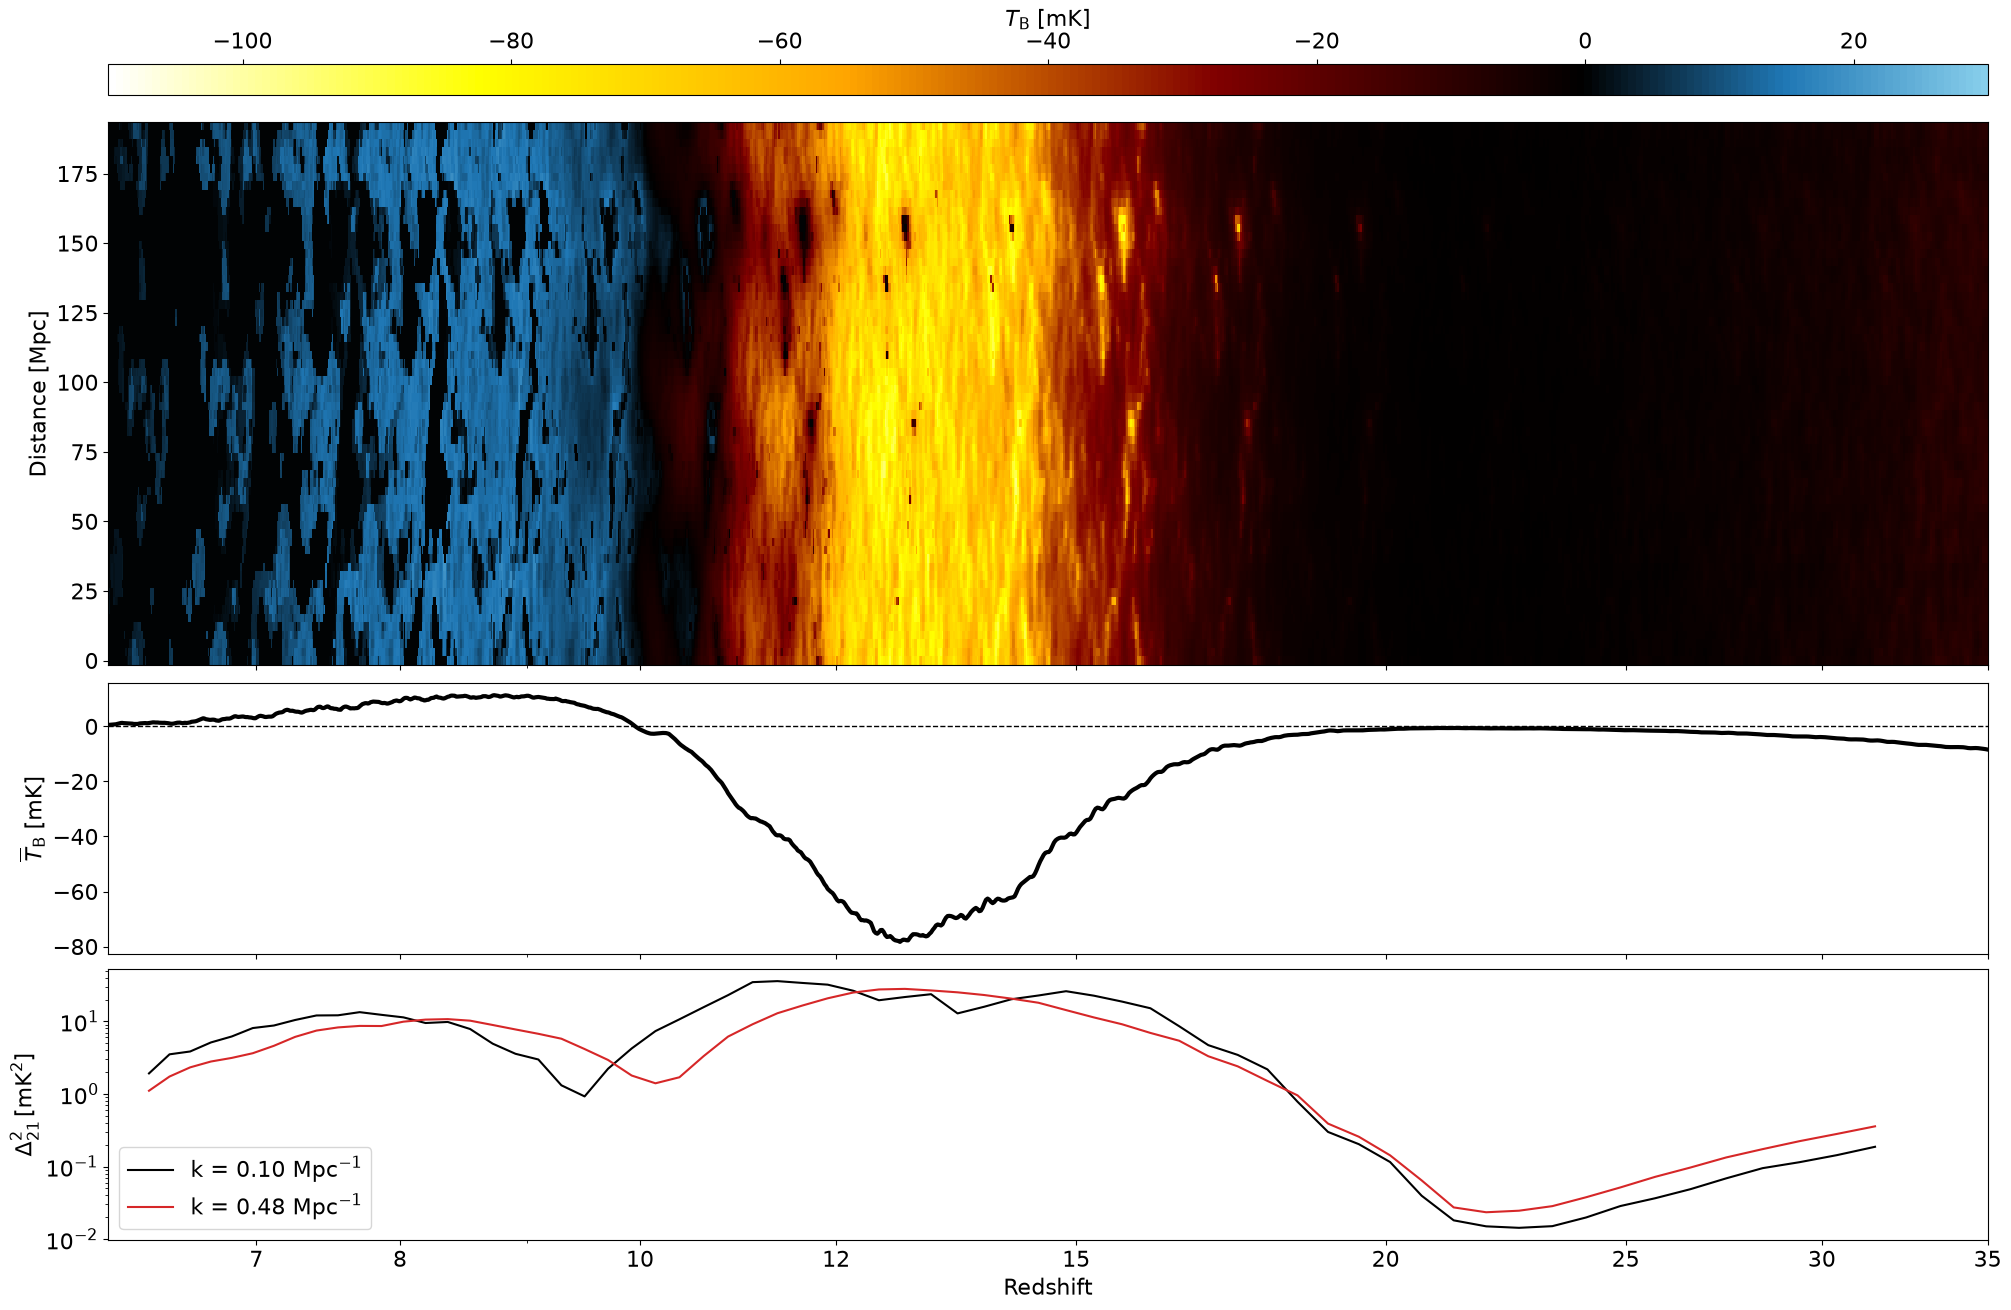

In [4]:
plt.rcParams["font.size"] = 16  # the font size of tuesday's plotting functions
fig, axes = plt.subplots(
    3,
    1,
    figsize=(20, 13),
    sharex=True,
    layout="constrained",
    gridspec_kw={"height_ratios": [2, 1, 1]},
)
vmin, vmax = -110, 30
plot_lightcone_slice(
    tb,
    box_length,
    z,
    ax=axes[0],
    cmap=eor_colormap(vmin, vmax),
    vmin=vmin,
    vmax=vmax,
    logx=True,
    xlabel="",
)
# plot_lightcone_slice puts the colour bar on the right; put it above the lightcone.
mesh = axes[0].collections[0]
mesh.colorbar.remove()
fig.colorbar(mesh, ax=axes[0], location="top", aspect=60, label=r"$T_{\rm B}$ [mK]")

axes[1].plot(z, tb.mean(axis=(0, 1)).value, color="k", lw=3)
axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set_ylabel(r"$\overline{T}_{\rm B}$ [mK]")

for i, colour in zip(at, ["k", "C3"], strict=True):
    plot_1d_power_spectrum_z(
        ps1d,
        at_k=k[i].value,
        ax=axes[2],
        log=[True, True],
        color=colour,
        legend=f"k = {k[i].value:.2f} Mpc$^{{-1}}$",
        legend_kwargs={"loc": "lower left"},
        xlabel="Redshift",
    )

axes[-1].set_xticks([6, 7, 8, 10, 12, 15, 20, 25, 30, 35])
axes[-1].xaxis.set_major_formatter(ScalarFormatter())
axes[-1].xaxis.set_minor_formatter(NullFormatter())
axes[-1].set_xlim(z[0], z[-1]);

## A light-plane

An angular lightconer takes the latitude and longitude of its directions (in radians),
the distances of its slices, and the quantities to make. Here the directions are 2048
points on the equator, over 22.5 degrees of longitude, and the slices are one cell apart
from z = 7 to 30, like the light-plane of 21cmFAST's lightcone tutorial. `los_velocity`
is the velocity along each line of sight, positive towards the observer.

`plot_angular_lightcone_slice` draws such a lightcone as a wedge of its true shape: each
value at its angle along the arc and at its comoving distance from the observer, whose
redshift labels the arcs. By default it has the colours of 21cmFAST's lightcone plots,
with zero in black, absorption from red to white and emission in blue, and with
`dark_mode=True` also their dark background. All plotting functions of `tuesday` take
`dark_mode`, and `tuesday.core.set_dark_mode(True)` makes all later plots dark.

In [5]:
n = 2048
arc = {"latitude": np.zeros(n), "longitude": np.linspace(0, np.pi / 8, n)}
common = {
    "min_redshift": 7.0,
    "max_redshift": 30.0,
    "resolution": cell,
    "cosmo": cosmo,
    "quantities": ("brightness_temp", "z_reion", "los_velocity"),
}
fast = FastAngularLightconer.between_redshifts(**arc, **common)
lc = construct_lightcone_from_cache(run, fast)
lc.lightcones["brightness_temp"].shape

(2048, 920)

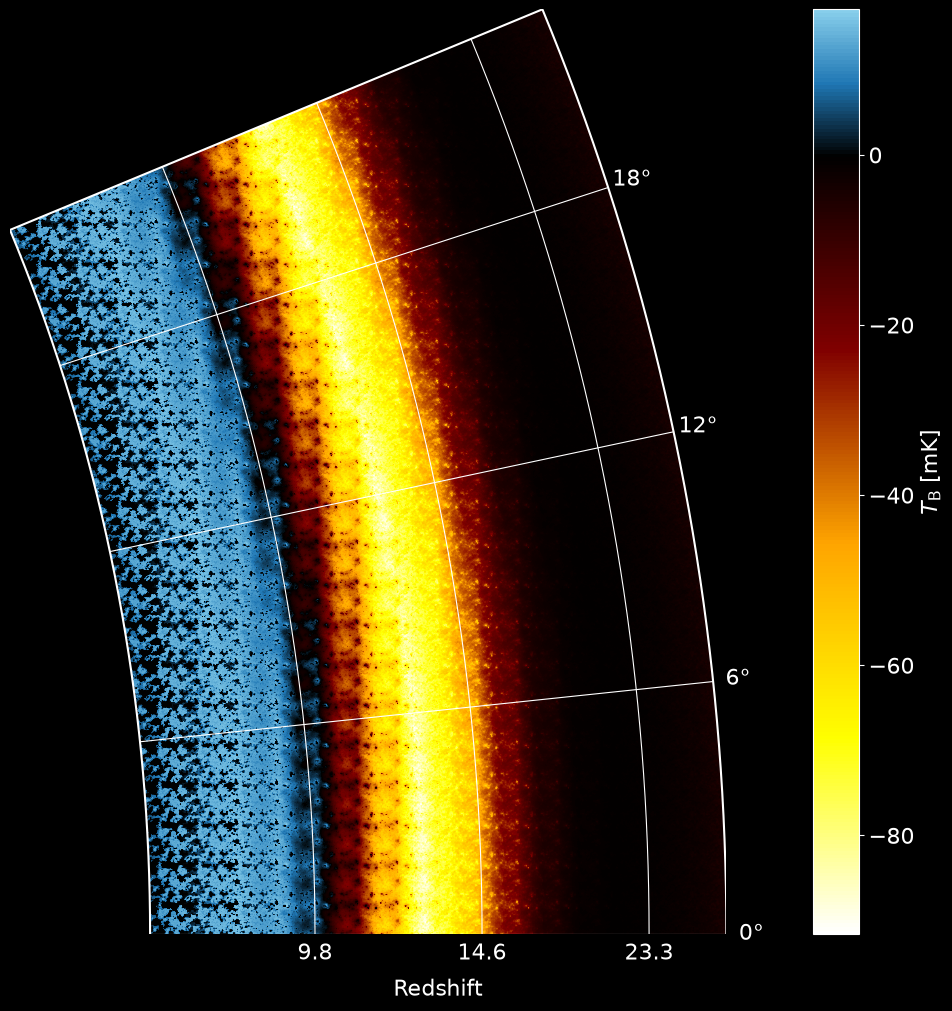

In [6]:
plot_angular_lightcone_slice(
    lc.lightcones["brightness_temp"] * un.mK,
    arc["longitude"] * un.rad,
    lc.lightcone_distances,
    redshift=lc.lightcone_redshifts,
    dark_mode=True,
);

## Sampling first or interpolating first

Each slice lies between two coeval boxes. 21cmFAST's `AngularLightconer` interpolates
the two boxes in redshift, cell by cell, and then samples the interpolated box at the
directions of the slice. Sampling each box at the directions first and interpolating
the samples gives the same slice, to rounding, since both steps are linear in the field.
The first costs about one operation per cell, the second about 16 per direction sampled
(`lightcones.CELLS_PER_SAMPLE`), so sampling first is cheaper when the box has more than
16 cells per direction.

`FastAngularLightconer` chooses for each slice. `tile_first=True` or `False` forces one
way. The interpolation of `z_reion` ("mean_max") is not linear in the boxes, so when
sampling first it is applied at the eight cells around each direction before they are
weighted, which again gives the same slice.

In [7]:
print("cells per direction:", 64**3 / n)
print("samples first:", lightcones.samples_first(64**3, n), fast.samples_first(64**3))

results = {}
for name, lightconer in [
    ("21cmFAST AngularLightconer", p21c.AngularLightconer.between_redshifts(**arc, **common)),
    ("sample first", fast),
    ("interpolate first", FastAngularLightconer.between_redshifts(**arc, tile_first=False, **common)),
]:
    start = time.perf_counter()
    results[name] = construct_lightcone_from_cache(run, lightconer)
    print(f"{name:28s} {time.perf_counter() - start:5.1f} s")

cells per direction: 128.0
samples first: True True


21cmFAST AngularLightconer     7.6 s


sample first                   5.0 s


interpolate first              8.4 s


In [8]:
reference = results["21cmFAST AngularLightconer"].lightcones
for name in ("sample first", "interpolate first"):
    for q in reference:
        diff = np.abs(results[name].lightcones[q] - reference[q]).max()
        print(f"{name:18s} {q:16s} largest difference / largest value: {diff / np.abs(reference[q]).max():.1e}")

sample first       brightness_temp  largest difference / largest value: 8.3e-08
sample first       z_reion          largest difference / largest value: 0.0e+00
sample first       los_velocity     largest difference / largest value: 1.6e-07
interpolate first  brightness_temp  largest difference / largest value: 0.0e+00
interpolate first  z_reion          largest difference / largest value: 0.0e+00
interpolate first  los_velocity     largest difference / largest value: 0.0e+00


The times include reading the boxes from the cache, which both ways share. The gain
grows with the number of cells per direction: a 1500^3 box with a ring of 2^15
directions has about 10^5. For a 512^3 box and a ring of 2^15 directions, one slice of
the density took 1.4 s with 21cmFAST's `AngularLightconer` and 9 ms sampling first, on
one thread (measured for the same change in 21cmFAST). Sampling first differs from
21cmFAST at the level of float32 rounding, since cosmotile returns samples of a float32
box in float32.

## Pixels that average several directions

A pixel much larger than the cells aliases the field if it takes the value at one
direction. With `n_subsamples`, each pixel is the mean over several directions, given
sub-sample by sub-sample: `latitude` and `longitude` are `np.ravel` of arrays of shape
`(n_subsamples, n_pixels)`. Here each of 512 pixels of a ring around the equator
averages four directions across its width. cosmotile projects the velocity on each direction before the average.

In [9]:
n_pixels, n_sub = 512, 4
width = 2 * np.pi / n_pixels
offsets = (np.arange(n_sub) + 0.5) / n_sub - 0.5
coarse = FastAngularLightconer.between_redshifts(
    latitude=np.zeros(n_sub * n_pixels),
    longitude=((np.arange(n_pixels) + 0.5 + offsets[:, None]) * width).ravel(),
    n_subsamples=n_sub,
    **common,
)
averaged = construct_lightcone_from_cache(run, coarse)
coarse.n_pixels, averaged.lightcones["brightness_temp"].shape

(512, (512, 920))

## HEALPix maps

`healpix_lightconer` makes a `FastAngularLightconer` whose slices are HEALPix maps, in
ring (default) or nested order, so `lightcone[:, i]` is the map of slice `i` and can be
used with healpy. With `subsample_level=k`, each pixel is the mean over its `4**k`
sub-pixels, the pixels of `Nside * 2**k` that tile it.

`plot_healpix_map` plots one map, e.g. `lightcone[:, i]`: the full sky in the Mollweide
projection, or a patch in longitude and latitude.

`nside_for_cell_size` gives the smallest Nside whose pixels are no larger than a cell at
a distance, and `subsample_level_for_cell_size` the level that makes the sub-pixels no
larger than a cell. For this box, out to z = 9, they ask for many more pixels than a
quick example can use, so the maps below, from z = 8 to 9, are coarser than the cells
and average 16 sub-pixels per pixel.

In [10]:
far = cosmo.comoving_distance(9.0)
print("Nside for one cell at z = 9:", lightcones.nside_for_cell_size(cell, far))
print("sub-pixel level for Nside 16:", lightcones.subsample_level_for_cell_size(16, cell, far))

bt = {**common, "min_redshift": 8.0, "max_redshift": 9.0, "quantities": ("brightness_temp",)}
sky = healpix_lightconer(16, subsample_level=2, **bt)
maps = construct_lightcone_from_cache(run, sky)
maps.lightcones["brightness_temp"].shape

Nside for one cell at z = 9: 4096
sub-pixel level for Nside 16: 8


(3072, 92)

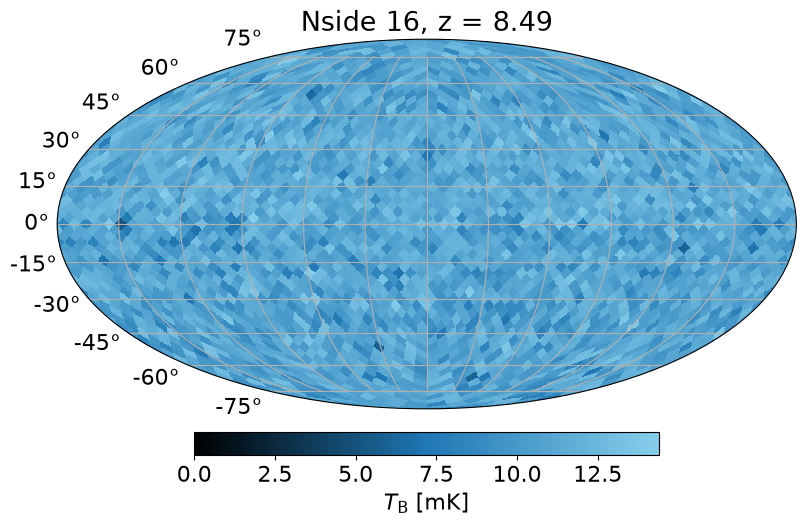

In [11]:
i = len(maps.lightcone_redshifts) // 2
plot_healpix_map(
    maps.lightcones["brightness_temp"][:, i] * un.mK,
    16,
    title=f"Nside 16, z = {maps.lightcone_redshifts[i]:.2f}",
);

The box is 192 Mpc on a side and is tiled periodically, so at a distance of about 9 Gpc
the same structures repeat every 192 / 9000 radians (about 1.2 degrees) on the sky. A
patch smaller than that has no repeated structures. `disc_pixels` gives the pixels whose
centres lie within a radius of a point, e.g. a patch the size of a telescope's beam, and
`healpix_lightconer` takes them as `pixels`, and so does `plot_healpix_map`.

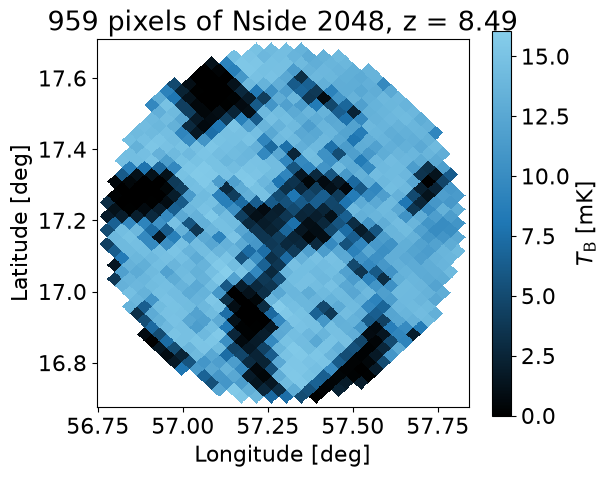

In [12]:
nside = 2048
patch = lightcones.disc_pixels(nside, 1.0 * un.rad, 0.3 * un.rad, 0.5 * un.deg)
disc = healpix_lightconer(nside, pixels=patch, subsample_level=1, **bt)
disc_lc = construct_lightcone_from_cache(run, disc)

plot_healpix_map(
    disc_lc.lightcones["brightness_temp"][:, i] * un.mK,
    nside,
    pixels=patch,
    title=f"{patch.size} pixels of Nside {nside}, z = {disc_lc.lightcone_redshifts[i]:.2f}",
);

`degrade` averages full-sky maps to a coarser Nside. Each coarse pixel is the mean of the
fine pixels that tile it, so the mean of each map does not change.

In [13]:
coarse_maps = lightcones.degrade(maps.lightcones["brightness_temp"], 4)
print(coarse_maps.shape)
print(np.allclose(coarse_maps.mean(axis=0), maps.lightcones["brightness_temp"].mean(axis=0)))

(192, 92)
True


`FastAngularLightconer` and `healpix_lightconer` also work with `py21cmfast.run_lightcone`,
including its dv/dr correction and RSDs, which are then applied to the averaged pixels.